# What drives urban heat? Factor analysis with SHAP

**Question:** inside a city, which surface factors make some places hotter than others, and by how much?

**Method:** an XGBoost model predicts the **LST anomaly** (°C above / below the scene median) from *physical,
nameable* factors only: vegetation (NDVI, red-edge), built-up (NDBI, built-up share), water (MNDWI, leaf/surface
water), surface brightness (hyperspectral albedo), SWIR mineral / concrete absorption, and terrain. The thermal
context is left out on purpose: "this spot is usually hot" predicts well but does not explain *why*.
**SHAP** splits every prediction into °C contributions per factor (exact TreeSHAP from XGBoost).

**Read the results as associations the model learned from 281 cities, not proven causes.** Effect sizes are
the slope of a factor's contribution over its typical range, for a stated step (e.g. +0.1 NDVI).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from urbanheat.config import load_config
from urbanheat.models import features as F, baselines as B

cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.precision", 3)

X, info, hs_cols = F.table(H5)
print(f"pixel table: {len(X):,} pixels x {X.shape[1]} features |", info.split.value_counts().to_dict())

from urbanheat.drivers import attribution as A

y = info.y_anom.to_numpy()
cols = F.DRIVERS
m, model = B.run("xgb_anom_drivers", "xgb", X[cols], y, info, RUNS, "anomaly")
print(f"driver model ({len(cols)} factors): test MAE {m['test']['mae']:.2f} °C, R2 {m['test']['r2']:.3f} | val R2 {m['val']['r2']:.3f}")

pixel table: 842,935 pixels x 150 features | {'train': 640935, 'test': 112000, 'val': 90000}


C:\miniforge3\envs\pygile\lib\site-packages\xgboost\core.py:751: UserWarning: [15:58:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


driver model (13 factors): test MAE 1.96 °C, R2 0.246 | val R2 0.347


## Contributions on held-out cities

SHAP is computed on the validation + test pixels (cities the model did not train on).

202,000 pixels | base value -0.11 °C | check: SHAP sum reproduces predictions: True


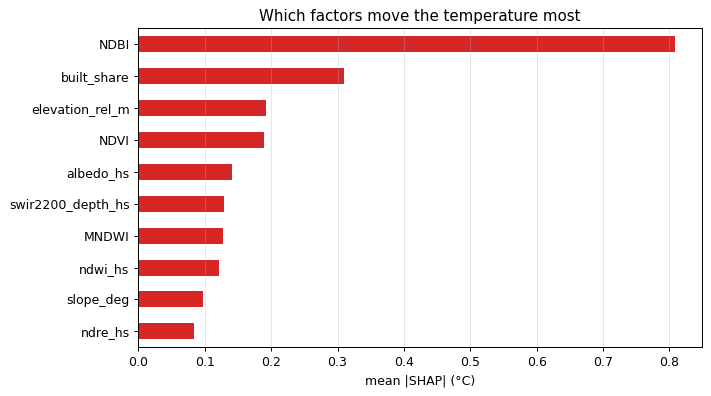

In [2]:
ev = info.split.isin(["val", "test"]).to_numpy()
Xe, ie = X.loc[ev, cols], info[ev]
shap, base = A.contributions(model, Xe)
print(f"{len(Xe):,} pixels | base value {base:+.2f} °C | check: SHAP sum reproduces predictions: "
      f"{np.allclose(shap.sum(1) + base, model.predict(Xe), atol=1e-3)}")
rank = A.ranking(shap.drop(columns=F.SENSOR_COLS))
fig, ax = plt.subplots(figsize=(8, 4.5))
rank[::-1].plot.barh(ax=ax, color="tab:red"); ax.set_xlabel("mean |SHAP| (°C)")
ax.set_title("Which factors move the temperature most"); ax.grid(alpha=.3, axis="x"); plt.tight_layout(); plt.show()

## By factor group

Several indices measure nearly the same thing (NDVI and NDBI are strongly anti-correlated in cities), and SHAP
then splits the credit between them somewhat arbitrarily. Summing the contributions within each group of factors
gives a more robust answer to "vegetation or buildings or water?".

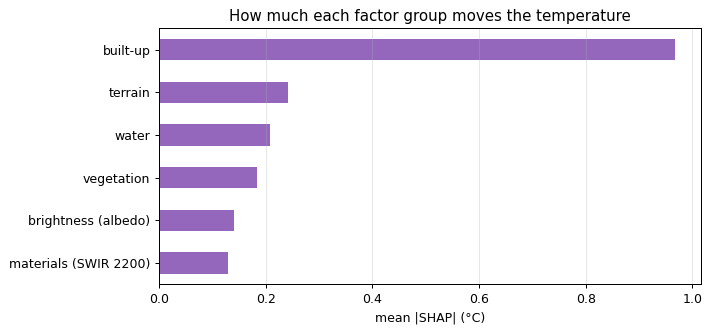

built-up                 0.52
terrain                  0.13
water                    0.11
vegetation               0.10
brightness (albedo)      0.08
materials (SWIR 2200)    0.07
Name: share of explained variation, dtype: float32

In [3]:
gs = A.group(shap)
grank = gs.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
grank[::-1].plot.barh(ax=ax, color="tab:purple")
ax.set_xlabel("mean |SHAP| (°C)"); ax.set_title("How much each factor group moves the temperature"); ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
(grank / grank.sum()).round(2).rename("share of explained variation")

## Direction and size of each effect

`effect_c_per_step`: change in the pixel's temperature anomaly (°C) when the factor increases by `step`, read
from the model over the factor's 5–95 % range. Negative = cooling.

In [4]:
eff = A.effects(shap, Xe)
eff.round(3)

,feature,step,effect_c_per_step,range_lo,range_hi,mean_abs_shap
0,NDBI,0.10,0.633,-0.372,0.105,0.809
1,built_share,0.10,0.220,0.000,0.429,0.309
2,elevation_rel_m,10.00,0.013,-52.000,80.000,0.193
3,NDVI,0.10,-0.106,0.149,0.794,0.190
4,albedo_hs,0.05,0.019,0.109,0.260,0.141
5,swir2200_depth_hs,0.02,0.038,-0.130,0.036,0.129
6,MNDWI,0.10,0.062,-0.560,-0.220,0.127
7,ndwi_hs,0.10,0.099,-0.141,0.113,0.122
8,slope_deg,5.00,-0.137,0.500,13.000,0.098
9,ndre_hs,0.10,0.049,0.048,0.466,0.085


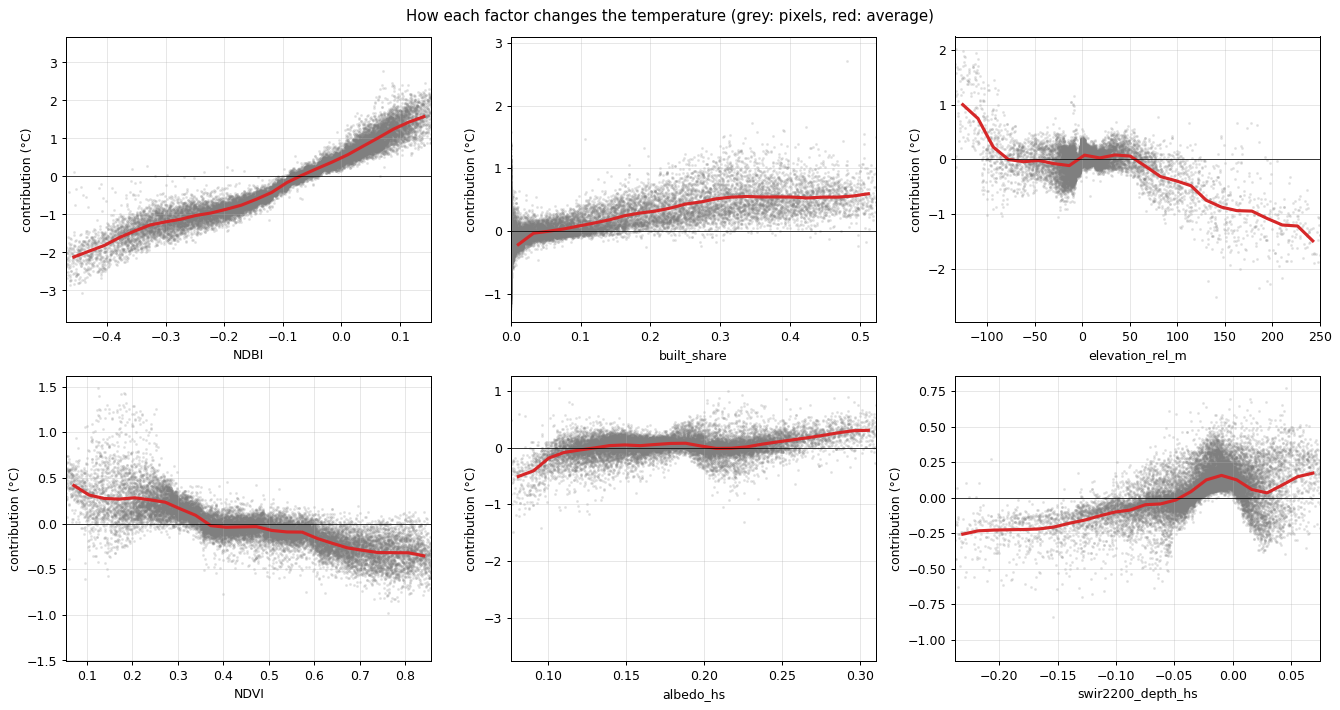

In [5]:
top = [f for f in rank.index[:6]]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
rng = np.random.default_rng(0)
sub = rng.choice(len(Xe), min(20000, len(Xe)), replace=False)
for a, f in zip(ax.ravel(), top):
    x, s = Xe[f].to_numpy(), shap[f].to_numpy()
    lo, hi = np.nanpercentile(x, [1, 99])
    a.scatter(x[sub], s[sub], s=2, alpha=.15, color="tab:gray")
    bins = np.linspace(lo, hi, 25); mid = (bins[1:] + bins[:-1]) / 2
    mean = [s[(x >= b0) & (x < b1)].mean() if ((x >= b0) & (x < b1)).sum() > 30 else np.nan for b0, b1 in zip(bins[:-1], bins[1:])]
    a.plot(mid, mean, color="tab:red", lw=2.5)
    a.axhline(0, color="k", lw=.6); a.set_xlim(lo, hi); a.set_xlabel(f); a.set_ylabel("contribution (°C)"); a.grid(alpha=.3)
fig.suptitle("How each factor changes the temperature (grey: pixels, red: average)"); plt.tight_layout(); plt.show()

## Does it differ by climate?

Mean |SHAP| per factor in each climate group. Different cities may need different mitigation.

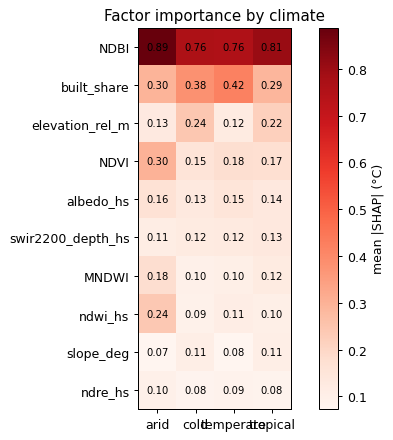

effect (°C per step) by climate:


,arid,cold,temperate,tropical
feature,,,,
MNDWI,0.02,0.03,0.08,0.05
NDBI,0.72,0.60,0.61,0.62
NDVI,-0.15,-0.11,-0.10,-0.10
albedo_hs,0.01,-0.10,-0.09,0.04
built_share,0.15,0.36,0.24,0.21
elevation_rel_m,0.06,-0.05,-0.01,0.01
ndre_hs,0.05,0.08,0.06,0.05
ndwi_hs,0.05,-0.01,0.01,0.10
slope_deg,-0.15,-0.22,-0.18,-0.14


In [6]:
pc = A.ranking(shap.drop(columns=F.SENSOR_COLS), ie.climate_group).loc[rank.index]
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pc.values, cmap="Reds"); ax.set_xticks(range(pc.shape[1])); ax.set_xticklabels(pc.columns)
ax.set_yticks(range(len(pc))); ax.set_yticklabels(pc.index)
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]):
        ax.text(j, i, f"{pc.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, label="mean |SHAP| (°C)"); ax.set_title("Factor importance by climate")
plt.tight_layout(); plt.show()
eff_c = pd.DataFrame({g: A.effects(shap[(ie.climate_group == g).to_numpy()], Xe[(ie.climate_group == g).to_numpy()])
                      .set_index("feature").effect_c_per_step for g in sorted(ie.climate_group.unique())})
print("effect (°C per step) by climate:"); eff_c.round(2)

## Why is this spot hot? One test city

Every pixel's anomaly split into factor contributions. Red = this factor makes the spot hotter, blue = cooler.

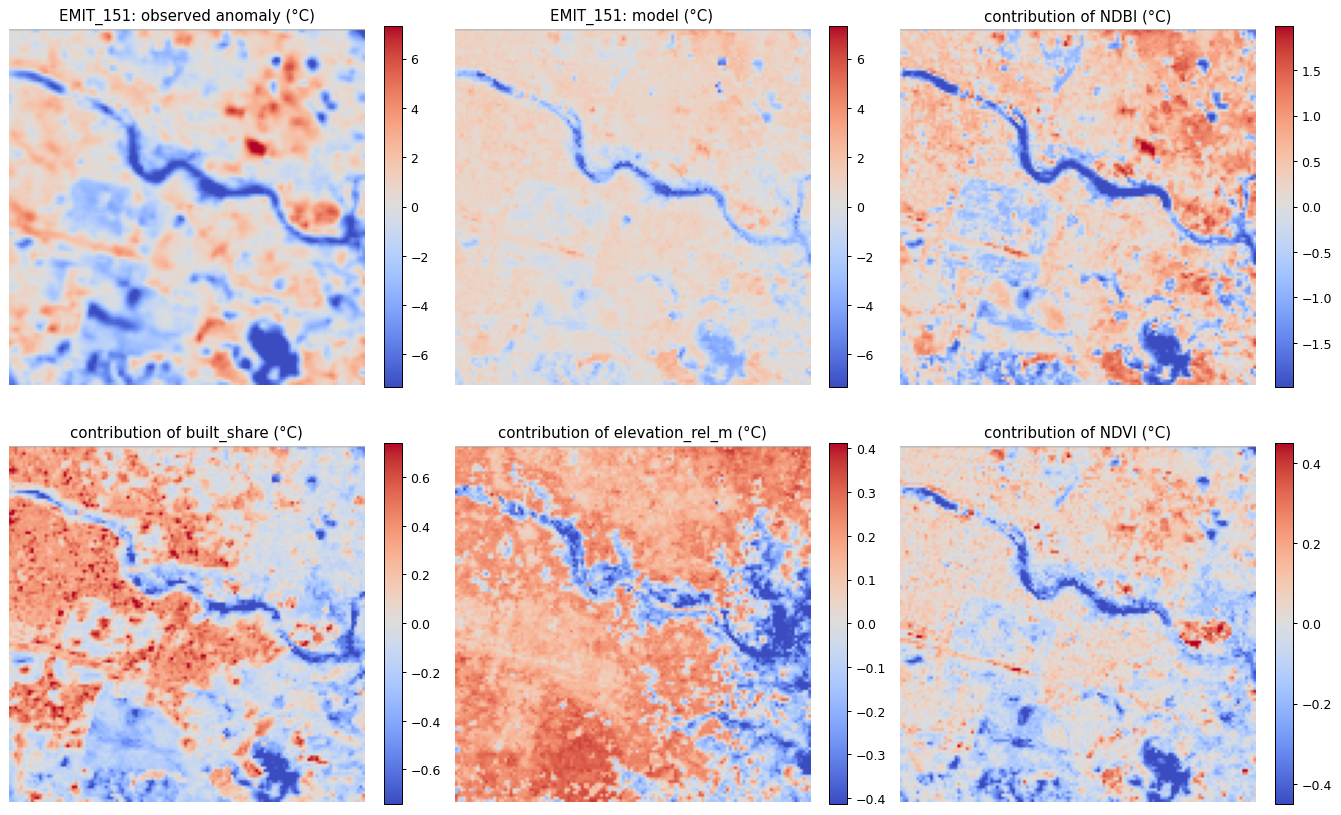

EMIT_151: model R2 on this scene 0.47


In [7]:
import h5py
with h5py.File(H5) as f:
    test_pairs = [(k, g.attrs["n_valid"], g.attrs["climate_group"]) for k, g in f["pairs"].items() if g.attrs["split"] == "test"]
pid = max(test_pairs, key=lambda t: t[1])[0]
Xp, yp, vp = F.pair_table(H5, pid)
sp, _ = A.contributions(model, Xp[cols])
show = [f for f in rank.index[:4]]
def to_map(vals):
    out = np.full(vp.shape, np.nan, "float32"); out[vp] = vals; return out
fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))
pred = model.predict(Xp[cols])
lim = np.nanpercentile(np.abs(yp), 98)
for a, img, t in [(ax[0, 0], to_map(yp), "observed anomaly (°C)"), (ax[0, 1], to_map(pred), "model (°C)")]:
    im = a.imshow(img, cmap="coolwarm", vmin=-lim, vmax=lim); a.set_title(f"{pid}: {t}"); plt.colorbar(im, ax=a, fraction=0.046)
for a, f in zip([ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]], show):
    l2 = np.nanpercentile(np.abs(sp[f]), 98)
    im = a.imshow(to_map(sp[f].to_numpy()), cmap="coolwarm", vmin=-l2, vmax=l2); a.set_title(f"contribution of {f} (°C)")
    plt.colorbar(im, ax=a, fraction=0.046)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
print(f"{pid}: model R2 on this scene {B.scores(yp, pred)['r2']:.2f}")

## Save for the team (docs/CONTRACTS.md section 4)

In [8]:
out = RUNS / "xgb_anom_drivers" / "explain"
out.mkdir(parents=True, exist_ok=True)
g = []
for grp, sel in [("all", np.ones(len(ie), bool))] + [(c, (ie.climate_group == c).to_numpy()) for c in sorted(ie.climate_group.unique())]:
    e = A.effects(shap[sel], Xe[sel])
    g.append(pd.DataFrame(dict(feature=e.feature, mean_abs_shap=e.mean_abs_shap,
                               direction=np.sign(e.effect_c_per_step), effect_c_per_step=e.effect_c_per_step,
                               step=e.step, climate_group=grp)))
pd.concat(g).to_csv(out / "global_importance.csv", index=False)
print("saved", out / "global_importance.csv")

saved D:\urbanheat-data\runs\xgb_anom_drivers\explain\global_importance.csv


## Summary

**What makes parts of a city hotter** (model of the within-city anomaly from physical factors only; contributions
on held-out cities):

| Factor group | Share of the explained variation | Effect |
|---|---|---|
| **Built-up** (NDBI, built-up share) | **52 %** | +0.6 °C per +0.1 NDBI; +0.2 °C per +10 % built-up share |
| Terrain (relative elevation, slope) | 13 % | higher and steeper places are cooler (≈ −0.14 °C per +5° slope) |
| Water (MNDWI, leaf/surface water) | 11 % | water bodies are strongly cooler (rivers / lakes in the maps) |
| Vegetation (NDVI, red-edge) | 10 % | −0.1 °C per +0.1 NDVI *on top of* the built-up effect |
| Brightness (hyperspectral albedo) | 8 % | small; brighter surfaces slightly hotter in arid/tropical, cooler in cold/temperate |
| Materials (SWIR 2200 nm absorption) | 7 % | small |

1. **Built-up surfaces are the dominant driver** in every climate group. Converting built-up land back to
   vegetation (lower NDBI) is the strongest lever in this data.
2. Vegetation's own effect looks small because it is the mirror image of built-up (NDVI and NDBI are strongly
   anti-correlated): much of the "greening" effect is counted under built-up. Read the groups together.
3. Water bodies and low-lying river corridors are the clearest cool spots.
4. Albedo and SWIR material features matter, but less than land cover at 60 m. Albedo's effect changes sign by
   climate, so "cool roofs" need care: brightness at 60 m mixes roofs, bare soil and sand.
5. This model explains about 25 % of the within-city pattern on unseen cities; the rest needs the thermal context
   or spatial context (CNNs).

**Caveats:** associations learned from 281 cities, not causal proof; correlated factors share credit (use the
groups); 60 m pixels mix materials. Effects are what the what-if scenarios (Member 3) will build on.

Saved for the team: `runs/xgb_anom_drivers/explain/global_importance.csv`.